<a href="https://colab.research.google.com/github/Vigneshvar16/NLP_DSA/blob/main/Assignement_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


======== DATA ========
circulars=300 tokens=72698 | queries=60 (dev 40, held-out 20) | terms=25 | annotated occurrences=7200

======== TASK 3/2: FOPC ========
knowledge base: 40 rules, all well-formed
  F1 every employee with 10 yrs service gets a pension: False
  F2 ... and who has retired: True
  F3 some widow is the spouse of Raman: True
  F4 no retired employee lacks a pension: True
  F5 every pensioner is an employee: True
  F6 some employee receives every pension: False
  F7 exactly one retired employee has 10 yrs service: True
  F8 every child of Raman is his dependent: True
scope ambiguity (reading1 | reading2):
  every pensioner receives a pension: True | False
  every employee has a nominee: True | False
  a circular governs every revision: True | False
inference 1:
  descendant_of(tara, raman)   [R6 descendant is transitive through child_of]
      child_of(tara, arun)   [given]
      descendant_of(arun, raman)   [R7 child_of => descendant_of]
          child_of(arun, raman)

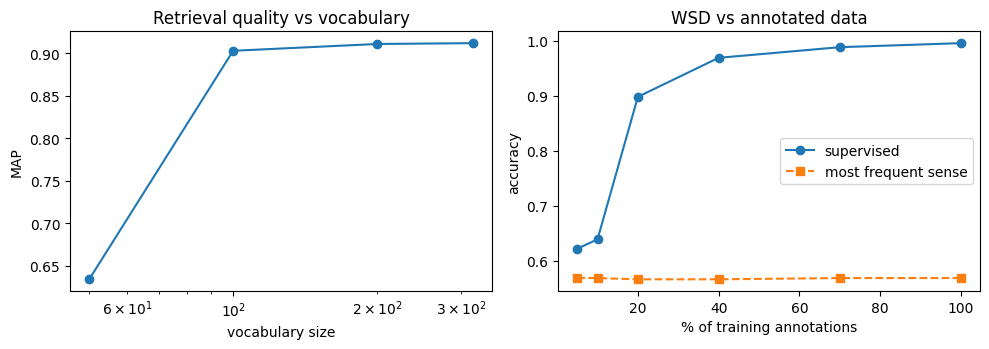

supervised accuracy within 1 point of its maximum from % of data: 70

======== TASK 11: COMPARISON ========
which-circular P@1: keyword 0.867 | sense-aware 0.867 | logical form: cannot rank circulars
yes/no claims: logical-form coverage 0.850, answer agreement on covered supported claims 170/170 | keyword retrieval cannot answer yes/no
run-time per query: keyword 0.3 ms | sense-aware 0.3 ms | logical form 13.2 ms
manual effort estimate (minutes, ASSUMED per-item times): {'rules': 600, 'grammar': 270, 'sense_inventory': 500, 'sense_annotation': 300.0, 'relevance': 900.0, 'second_annotator': 325.0} | total hours 48.2

======== TASK 12: NEW SCHEME ========
original grammar coverage on 40 new enquiries: 0/40 | modified slot-parser coverage: 40/40
yes/no accuracy vs gold rule: original design forced to a static 10-year rule 0.750 | modified (dated rules + SQL aggregation + cross-reference) 1.000 | modified run-time 0.07 ms/enquiry
SQL vs independent Python qualifying-service calculation ide

In [1]:
"""
DSA03 NLP - Assignment 4 (CO4): meaning-based enquiry + document search layer for a pension helpdesk.
Runs top to bottom in ONE Google Colab cell (CPU, ~1-2 min). Uses only: standard library, numpy, matplotlib, NLTK, scikit-learn
(all pre-installed in Colab). It does not read or download any of your files; it only fetches the small public NLTK data packs
(wordnet, POS tagger) and writes two small CSV/PNG files in the working folder.
DATA NOTE: the circulars, enquiries, sense annotations and relevance judgements are SYNTHETIC (generated here, fixed seed 42),
because real helpdesk data is not available. Replace the generator in section 0 by your real data to produce real figures.
"""
import random, re, math, time, sqlite3, collections, csv, datetime, warnings
import numpy as np
import matplotlib.pyplot as plt
import nltk
from nltk.sem import Valuation, Model, Assignment, Expression, root_semrep
from nltk.grammar import FeatureGrammar
from nltk.parse import FeatureChartParser
warnings.filterwarnings("ignore")
for _p in ("wordnet", "averaged_perceptron_tagger_eng"):
    try: nltk.download(_p, quiet=True)
    except Exception: pass
SEED = 42; random.seed(SEED); np.random.seed(SEED); rng = random.Random(SEED)
STAGES = []
class stage:                                   # records items / analysed / rejected / run-time for Task 10
    def __init__(s, name, n): s.name, s.n, s.ok = name, n, 0
    def __enter__(s): s.t = time.time(); return s
    def __exit__(s, *a): STAGES.append((s.name, s.n, s.ok, s.n - s.ok, round(time.time() - s.t, 2)))
def head(t): print("\n" + "=" * 8, t, "=" * 8)
def ci(vals, n=1000):                          # bootstrap 95% confidence interval (fixed seed)
    r = np.random.RandomState(SEED); v = np.array(vals, float)
    m = [r.choice(v, len(v)).mean() for _ in range(n)]; return round(float(np.percentile(m, 2.5)), 3), round(float(np.percentile(m, 97.5)), 3)

# ============ 0. SYNTHETIC DATA (documented generator) ============
RAW = """service|a period of employment in the government|years pension qualifying department gazette|a facility offered to the public at a counter|counter online delivery helpdesk portal
award|the grant of a sum or benefit to a person|sanctioned amount approved disbursed granted|an honour given for merit|medal ceremony merit trophy recognition
dependent|a person who relies on the employee for support|widow child spouse parents family|a variable that is controlled by another condition|variable function parameter value formula
benefit|a payment due under a scheme|gratuity commutation sanctioned scheme entitlement|an advantage or gain|advantage useful improvement gain outcome
revision|an upward change in pension rates|rates enhanced notification hike percent|the editing of a written text|draft edited text wording copy
grade|the pay level of a post|level post promotion increment designation|a class of quality or standard|quality standard marks assessment inspection
claim|a request for payment|application form submitted pensioner arrears|an assertion that something is true|statement assertion argument evidence proof
certificate|a document proving life or service|life proof treasury issued verification|a document proving academic qualification|degree diploma university marks graduate
cover|insurance protection for a person|insurance medical premium hospital scheme|the outer sheet of a file|file sheet folder binding printed
ceiling|the upper limit on an amount|limit maximum amount cap rupees|the inner upper surface of a room|room roof building plaster paint
relief|an additional allowance on pension|allowance dearness instalment percentage hike|release from pain or distress|pain comfort distress treatment medicine
bond|a written undertaking to serve or repay|undertaking surety repay executed stamp|a chemical link between atoms|chemical atoms molecule energy compound
scale|a graded range of pay|increments minimum maximum fitment bands|an instrument used for weighing|weighing kilogram weight instrument grams
cadre|the sanctioned strength of a service|strength sanctioned posts recruitment seniority|a trained group of political workers|party political workers organisation volunteers
commutation|conversion of part of a pension into a lump sum|lumpsum conversion fraction actuarial tables|the reversal of an electric current|electric current motor switch rotor
balance|the amount remaining in an account|remaining account passbook closing amount|a state of physical equilibrium|equilibrium posture stable steady gymnast
issue|a matter in dispute or doubt|dispute doubt clarification question raised|the release of a document or item|release dispatch distributed copies stamped
order|a formal directive of authority|directive government sanction issued office|the sequence in which things are arranged|sequence arranged alphabetical rank list
record|the history kept in a service book|book entries history verified attested|the best performance ever achieved|performance sport athlete broken champion
appeal|a request to a higher authority for review|review higher tribunal rejected petition|the quality of being attractive|attractive charm popular style fashion
authority|the office competent to sanction|competent sanctioning office head accounts|the power or permission to act|power permission delegated licence mandate
pay|the salary drawn by an employee|salary monthly drawn emoluments allowances|to settle a sum owed|settle sum owed cash cheque
term|the period of an office or appointment|period appointment tenure extension expiry|a word or expression|word expression dictionary vocabulary meaning
case|a matter or file of an individual|file individual hearing number pending|a container for carrying things|container carrying box luggage leather
settlement|the final payment of all dues|final dues payment retirement cleared|a small community or colony|colony community village residents"""
SENSES = {}
for line in RAW.split("\n"):
    t, g1, c1, g2, c2 = line.split("|"); SENSES[t] = [dict(gloss=g1, cues=c1.split()), dict(gloss=g2, cues=c2.split())]
TERMS = list(SENSES); TOPICS = [(t, s) for t in TERMS for s in (0, 1)]
FILL = "the office shall note that all concerned must ensure proper compliance regarding this matter as per existing rules and instructions issued earlier by government".split()
MON = "January February March April May June July August September October November December".split()
ORG_K = ["Finance Department", "Pension Directorate", "Treasury Office", "Accountant General", "Personnel Department"]
ORG_U = ["Directorate of Local Funds", "Board of Revenue"]
def make_sentence(t, s):
    ctx = rng.sample(SENSES[t][s]["cues"], 2)
    if rng.random() < 0.25: ctx.append(rng.choice(SENSES[t][1 - s]["cues"]))
    w = rng.sample(FILL, 6) + ctx; rng.shuffle(w); i = rng.randint(1, len(w)); return w[:i] + [t] + w[i:], i
DOCS, OCC, GOLD_ENT = [], [], []
for d in range(300):
    n, yr, ment = rng.randint(1, 999), rng.randint(1990, 2024), []
    org = rng.choice(ORG_K) if rng.random() < .9 else rng.choice(ORG_U); ment.append(("ORG", org))
    per = f"Shri {rng.choice('ABCDKMRS')}. {rng.choice(['Kumar','Rao','Nair','Iyer','Das'])}" if rng.random() < .88 else "Smt. Lakshmi Devi"; ment.append(("PERSON", per))
    amt = f"{rng.randint(5, 90) * 500:,}"; money = f"Rs. {amt}" if rng.random() < .92 else f"{amt} rupees"; ment.append(("MONEY", money))
    date = f"{rng.randint(1, 28)} {rng.choice(MON)} {yr}"; ment.append(("DATE", date)); ment.append(("CIRC", f"No. {n}/{yr}"))
    sents = []
    for _ in range(24):
        if rng.random() < .55: t, s = TOPICS[d % 50]
        else: t, s = rng.choice(TERMS), (0 if rng.random() < .7 else 1)
        tk, i = make_sentence(t, s); sents.append(" ".join(tk)); OCC.append(dict(doc=d, toks=tk, i=i, term=t, sense=s))
    DOCS.append(f"Circular No. {n}/{yr} dated {date} issued by {org} to {per} regarding {money} . " + " . ".join(sents)); GOLD_ENT.append(ment)
STOP = set("a an the of to in for on and or is are was be been by with that this at as it its from which who what does do say about".split())
def tokenize(t): return [w for w in re.findall(r"[a-z]+", t.lower()) if w not in STOP]
QUERIES = []
qt = TOPICS[:]; rng.shuffle(qt)
for (t, s) in (qt * 2)[:60]:
    r = rng.random(); ctx = [rng.choice(SENSES[t][s]["cues"])] if r < .65 else ([rng.choice(SENSES[t][1 - s]["cues"])] if r < .8 else [])
    QUERIES.append(dict(text=" ".join(["what", "does", "the", "circular", "say", "about", t] + ctx), term=t, sense=s, rel={d for d in range(300) if d % 50 == TOPICS.index((t, s))}))
perm = rng.sample(range(60), 60); DEV, HELD = perm[:40], perm[40:]
ntok = sum(len(re.findall(r"\w+", d)) for d in DOCS)
head("DATA"); print(f"circulars={len(DOCS)} tokens={ntok} | queries={len(QUERIES)} (dev {len(DEV)}, held-out {len(HELD)}) | terms={len(TERMS)} | annotated occurrences={len(OCC)}")

# ============ TASK 3 (+2): FOPC knowledge base, model, inference ============
head("TASK 3/2: FOPC")
read = Expression.fromstring
KB = ["all x.((employee(x) & service10(x) & retired(x)) -> exists y.(pension(y) & receive(x,y)))", "all x.(pensioner(x) -> employee(x))",
 "all x y.((widow(x) & spouse_of(x,y) & pensioner(y)) -> exists z.(family_pension(z) & receive(x,z)))", "all x y.((child_of(x,y) & pensioner(y) & minor(x)) -> dependent_of(x,y))",
 "all x y.(spouse_of(x,y) -> dependent_of(x,y))", "all x y z.((child_of(x,y) & descendant_of(y,z)) -> descendant_of(x,z))", "all x y.(child_of(x,y) -> descendant_of(x,y))",
 "-exists x.(employee(x) & -retired(x) & pensioner(x))", "all x.(employee(x) -> exists y.(scheme(y) & covered_by(x,y)))", "all x.((employee(x) & break_in_service(x) & short_break(x)) -> condoned(x))",
 "all x.(condoned(x) -> counts_as_qualifying(x))", "all x.(pensioner(x) -> exists y.(bank_account(y) & pays_into(x,y) & all z.((bank_account(z) & pays_into(x,z)) -> z = y)))",
 "all x y.((governs(x,y) & revision(y)) -> circular(x))", "all x.(commutation(x) -> exists y.(pension(y) & reduces(x,y)))", "-exists x.(dependent_of(x,x))",
 "all x y.(dependent_of(x,y) -> -dependent_of(y,x))", "all x.(family_pensioner(x) -> exists y.(pensioner(y) & (spouse_of(x,y) | child_of(x,y))))", "all x.(retired(x) -> employee(x))",
 "all x.((employee(x) & disabled(x)) -> exists y.(disability_pension(y) & receive(x,y)))", "all x.(qualifying_service(x) -> employee(x))"]
for n in (10, 15, 20, 25):
    for b in ("pension", "gratuity", "commutation", "medical", "leave_encashment"): KB.append(f"all x.((employee(x) & service_ge{n}(x) & retired(x)) -> eligible(x,{b}))")
with stage("FOPC KB parse", len(KB)) as st:
    for f in KB: read(f); st.ok += 1
print(f"knowledge base: {len(KB)} rules, all well-formed")
U = lambda *xs: set(xs)
VAL = Valuation([("employee", U("a", "b", "c", "d")), ("retired", U("a", "b")), ("pensioner", U("a", "b")), ("service10", U("a", "c")), ("widow", U("e")),
 ("pension", U("p1", "p2")), ("family_pension", U("fp1")), ("receive", U(("a", "p1"), ("b", "p2"), ("e", "fp1"))), ("spouse_of", U(("e", "a"), ("g", "b"))),
 ("child_of", U(("f", "a"))), ("dependent_of", U(("e", "a"), ("f", "a"))), ("circular", U("c1", "c2")), ("revision", U("r1", "r2")), ("governs", U(("c1", "r1"), ("c2", "r2"))),
 ("nominee", U("n1", "n2", "n3", "n4")), ("nominee_of", U(("n1", "a"), ("n2", "b"), ("n3", "c"), ("n4", "d"))), ("raman", "a"), ("sita", "b"), ("meena", "e")])
M = Model(VAL.domain, VAL); G = Assignment(VAL.domain)
F = [("F1 every employee with 10 yrs service gets a pension", "all x.((employee(x) & service10(x)) -> exists y.(pension(y) & receive(x,y)))", False),
 ("F2 ... and who has retired", "all x.((employee(x) & service10(x) & retired(x)) -> exists y.(pension(y) & receive(x,y)))", True),
 ("F3 some widow is the spouse of Raman", "exists x.(widow(x) & spouse_of(x,raman))", True),
 ("F4 no retired employee lacks a pension", "-exists x.(employee(x) & retired(x) & -pensioner(x))", True),
 ("F5 every pensioner is an employee", "all x.(pensioner(x) -> employee(x))", True),
 ("F6 some employee receives every pension", "exists x.(employee(x) & all y.(pension(y) -> receive(x,y)))", False),
 ("F7 exactly one retired employee has 10 yrs service", "exists x.(service10(x) & retired(x) & all y.((service10(y) & retired(y)) -> y = x))", True),
 ("F8 every child of Raman is his dependent", "all x.(child_of(x,raman) -> dependent_of(x,raman))", True)]
for name, f, exp in F:
    v = M.satisfy(read(f), G); print(f"  {name}: {v}"); assert v == exp
print("scope ambiguity (reading1 | reading2):")
SC = [("every pensioner receives a pension", "all x.(pensioner(x) -> exists y.(pension(y) & receive(x,y)))", "exists y.(pension(y) & all x.(pensioner(x) -> receive(x,y)))"),
 ("every employee has a nominee", "all x.(employee(x) -> exists y.(nominee(y) & nominee_of(y,x)))", "exists y.(nominee(y) & all x.(employee(x) -> nominee_of(y,x)))"),
 ("a circular governs every revision", "all y.(revision(y) -> exists x.(circular(x) & governs(x,y)))", "exists x.(circular(x) & all y.(revision(y) -> governs(x,y)))")]
for s, a, b in SC: print(f"  {s}: {M.satisfy(read(a), G)} | {M.satisfy(read(b), G)}")
FACTS = {("child_of", "arun", "raman"), ("child_of", "tara", "arun"), ("pensioner", "raman"), ("widow", "meena"), ("spouse_of", "meena", "raman")}
RULES = [("R7 child_of => descendant_of", ("descendant_of", "X", "Y"), [("child_of", "X", "Y")]),
 ("R6 descendant is transitive through child_of", ("descendant_of", "X", "Z"), [("child_of", "X", "Y"), ("descendant_of", "Y", "Z")]),
 ("R3 widow of a pensioner is eligible for family pension", ("eligible_fp", "X"), [("widow", "X"), ("spouse_of", "X", "Y"), ("pensioner", "Y")])]
def solve(body, facts, b):
    if not body: yield b; return
    pat = body[0]
    for f in list(facts):
        if len(f) != len(pat) or f[0] != pat[0]: continue
        nb, ok = dict(b), True
        for p, v in zip(pat[1:], f[1:]):
            if p[0].isupper():
                if nb.setdefault(p, v) != v: ok = False; break
            elif p != v: ok = False; break
        if ok: yield from solve(body[1:], facts, nb)
def forward(facts, rules):
    prov = {f: ("given", []) for f in facts}; ch = True
    while ch:
        ch = False
        for nm, hd, body in rules:
            for b in list(solve(body, set(prov), {})):
                new = (hd[0],) + tuple(b.get(a, a) for a in hd[1:])
                if new not in prov: prov[new] = (nm, [(bd[0],) + tuple(b.get(a, a) for a in bd[1:]) for bd in body]); ch = True
    return prov
PROV = forward(FACTS, RULES)
def proof(f, ind=2):
    r, prem = PROV[f]; print(" " * ind + f"{f[0]}({', '.join(f[1:])})   [{r}]")
    for p in prem:
        if PROV[p][0] != "given": proof(p, ind + 4)
        else: print(" " * (ind + 4) + f"{p[0]}({', '.join(p[1:])})   [given]")
print("inference 1:"); proof(("descendant_of", "tara", "raman")); print("inference 2:"); proof(("eligible_fp", "meena"))
NEG = {("receive", "kumar", "pension")}
def ask(f): return "TRUE" if f in PROV else ("FALSE" if f in NEG else "UNKNOWN")
print("verifiability:", ask(("descendant_of", "tara", "raman")), ask(("receive", "kumar", "pension")), ask(("eligible_fp", "sita")))
SYN = {"get": "receive", "gets": "receive", "receive": "receive", "receives": "receive", "paid": "receive", "granted": "receive", "recipient": "receive", "entitled": "receive", "draw": "receive", "draws": "receive"}
def canon(q):
    w = re.findall(r"[A-Za-z]+", q); subj = next(x.lower() for x in w[1:] if x[0].isupper())
    rel = next(SYN[x.lower()] for x in w if x.lower() in SYN); obj = "pension" if "pension" in q.lower() else "?"; return (rel, subj, obj)
for q in ["Does Raman get a pension?", "Is a pension paid to Raman?", "Has Raman been granted a pension?", "Is Raman a recipient of a pension?", "Is Raman entitled to a pension?"]: print("  canonical:", canon(q), "<-", q)

# ============ TASK 4: named entities ============
head("TASK 4: NER")
MONRE = "|".join(MON)
PAT = [("DATE", re.compile(rf"\b\d{{1,2}} (?:{MONRE}) \d{{4}}")), ("CIRC", re.compile(r"No\. \d+/\d{4}")), ("MONEY", re.compile(r"Rs\. [\d,]+")),
       ("PERSON", re.compile(r"Shri [A-Z]\. [A-Z][a-z]+")), ("ORG", re.compile("|".join(ORG_K)))]
def ner(text): return [(ty, m.group()) for ty, p in PAT for m in p.finditer(text)]
with stage("NER (circulars)", len(DOCS)) as st:
    pred = [ner(d) for d in DOCS]; st.ok = sum(1 for p in pred if p)
cnt = collections.Counter(ty for p in pred for ty, _ in p); print("entity counts:", dict(cnt))
allm = [(i, m) for i, g in enumerate(GOLD_ENT) for m in g]; samp = rng.sample(allm, 200)
okm = sum(1 for i, m in samp if m in pred[i]); print(f"accuracy on 200 sampled gold mentions: {okm/200:.3f}")
byt = collections.defaultdict(lambda: [0, 0])
for i, (ty, tx) in samp: byt[ty][1] += 1; byt[ty][0] += (ty, tx) in pred[i]
print("per type recall:", {k: f"{a}/{b}" for k, (a, b) in byt.items()})
tp = sum(1 for i, p in enumerate(pred) for m in p if m in GOLD_ENT[i]); print(f"precision over all circulars: {tp/max(1,sum(len(p) for p in pred)):.3f}")

# ============ TASK 5: semantic grammar (NLTK feature grammar, lambda semantics) ============
head("TASK 5: SEMANTIC GRAMMAR")
NOUNS = "employee pensioner widow child spouse pension gratuity circular scheme dependent nominee service".split()
TV = {"receives": "receive", "claims": "claim", "draws": "draw", "completes": "complete", "governs": "govern", "supports": "support"}
IV = {"qualifies": "qualify", "retires": "retire", "dies": "die"}
ADJ = "retired eligible disabled qualifying".split(); PN = "raman sita kumar meena".split(); PREP = "with of from under".split()
g = r"""
% start S
S[SEM=<?np(?vp)>] -> NP[SEM=?np] VP[SEM=?vp]
S[SEM=<(?s1 & ?s2)>] -> S[SEM=?s1] 'and' S[SEM=?s2]
NP[SEM=<?d(?n)>] -> Det[SEM=?d] N[SEM=?n]
NP[SEM=?p] -> PN[SEM=?p]
NP[SEM=<\P.exists x.(?n(x) & P(x))>] -> N[SEM=?n]
N[SEM=<\x.(?n(x) & ?pp(x))>] -> N[SEM=?n] PP[SEM=?pp]
N[SEM=<\x.(?n(x) & ?r(x))>] -> N[SEM=?n] RC[SEM=?r]
N[SEM=<\x.(?a(x) & ?n(x))>] -> Adj[SEM=?a] N[SEM=?n]
RC[SEM=?v] -> 'who' VP[SEM=?v]
VP[SEM=?v] -> IV[SEM=?v]
VP[SEM=<?t(?np)>] -> TV[SEM=?t] NP[SEM=?np]
VP[SEM=<\x.(?v1(x) & ?v2(x))>] -> VP[SEM=?v1] 'and' VP[SEM=?v2]
VP[SEM=<\x.(?v(x) & ?pp(x))>] -> VP[SEM=?v] PP[SEM=?pp]
PP[SEM=<?p(?np)>] -> P[SEM=?p] NP[SEM=?np]
Det[SEM=<\P Q.all x.(P(x) -> Q(x))>] -> 'every'
Det[SEM=<\P Q.all x.(P(x) -> Q(x))>] -> 'each'
Det[SEM=<\P Q.exists x.(P(x) & Q(x))>] -> 'some'
Det[SEM=<\P Q.exists x.(P(x) & Q(x))>] -> 'a'
Det[SEM=<\P Q.exists x.(P(x) & Q(x))>] -> 'an'
Det[SEM=<\P Q.-exists x.(P(x) & Q(x))>] -> 'no'
Det[SEM=<\P Q.exists x.(P(x) & all y.(P(y) -> y = x) & Q(x))>] -> 'the'
"""
for n in NOUNS: g += f"N[SEM=<\\x.{n}(x)>] -> '{n}'\n"
for w, p in TV.items(): g += f"TV[SEM=<\\X x.X(\\y.{p}(x,y))>] -> '{w}'\n"
for w, p in IV.items(): g += f"IV[SEM=<\\x.{p}(x)>] -> '{w}'\n"
for a in ADJ: g += f"Adj[SEM=<\\x.{a}(x)>] -> '{a}'\n"
for p in PN: g += f"PN[SEM=<\\P.P({p})>] -> '{p}'\n"
for p in PREP: g += f"P[SEM=<\\X x.X(\\y.{p}(x,y))>] -> '{p}'\n"
GR = FeatureGrammar.fromstring(g); PARSER = FeatureChartParser(GR)
LEX = set(NOUNS) | set(TV) | set(IV) | set(ADJ) | set(PN) | set(PREP) | {"every", "each", "some", "a", "an", "no", "the", "who", "and"}
print(f"grammar rules with a semantic attachment: {len(GR.productions())}")
assert len(GR.productions()) >= 50
def analyse(sent):
    tr = next(PARSER.parse(sent.split()), None); return None if tr is None else (tr, root_semrep(tr).simplify())
for s in ["every employee receives a pension", "raman retires and sita receives a gratuity", "every employee who completes service receives a pension", "no widow claims a pension"]:
    tr, sem = analyse(s); print(f"\n  '{s}'  ->  {sem}")
    def walk(t, d=2):                                        # bottom-up: semantic value at every node, reductions applied
        if isinstance(t, str): return
        for c in t: walk(c, d + 2)
        lab = t.label(); print(" " * d + f"{str(lab).split('[')[0]:4s} {str(lab['SEM'].simplify())[:95]}")
    walk(tr)
# enquiry set (200): 170 inside the grammar + 30 outside it (negation, counting, time, unknown vocabulary)
NT, TVl, IVl = NOUNS[:-1], list(TV), list(IV)
def inst():
    k = rng.randint(1, 9); n1, n2, n3 = rng.choice(NT), rng.choice(NT), rng.choice(NT); tv, tv2, iv = rng.choice(TVl), rng.choice(TVl), rng.choice(IVl); pn, pn2 = rng.choice(PN), rng.choice(PN); a = rng.choice(ADJ[:3])
    T = {1: (f"every {n1} {tv} a {n2}", f"all x.({n1}(x) -> exists y.({n2}(y) & {TV[tv]}(x,y)))"),
     2: (f"every {n1} who {tv} {n3} {tv2} a {n2}", f"all x.(({n1}(x) & exists y.({n3}(y) & {TV[tv]}(x,y))) -> exists z.({n2}(z) & {TV[tv2]}(x,z)))"),
     3: (f"some {n1} {iv}", f"exists x.({n1}(x) & {IV[iv]}(x))"), 4: (f"no {n1} {tv} a {n2}", f"-exists x.({n1}(x) & exists y.({n2}(y) & {TV[tv]}(x,y)))"),
     5: (f"{pn} {tv} a {n2}", f"exists y.({n2}(y) & {TV[tv]}({pn},y))"), 6: (f"every {a} {n1} {iv}", f"all x.(({a}(x) & {n1}(x)) -> {IV[iv]}(x))"),
     7: (f"every {n1} with a {n2} {iv}", f"all x.(({n1}(x) & exists y.({n2}(y) & with(x,y))) -> {IV[iv]}(x))"),
     8: (f"{pn} {iv} and {pn2} {tv} a {n2}", f"({IV[iv]}({pn}) & exists y.({n2}(y) & {TV[tv]}({pn2},y)))"),
     9: (f"{pn} {tv} a {n2} and {tv2} a {n3}", f"(exists y.({n2}(y) & {TV[tv]}({pn},y)) & exists z.({n3}(z) & {TV[tv2]}({pn},z)))")}
    return T[k]
ENQ = [inst() for _ in range(170)]
OUT = [(f"every {rng.choice(NT)} does not {rng.choice(['receive','claim'])} a {rng.choice(NT)}", None) for _ in range(10)] + \
      [(f"every {rng.choice(NT)} with more than ten {rng.choice(NT)} {rng.choice(TVl)} a {rng.choice(NT)}", None) for _ in range(8)] + \
      [(f"every {rng.choice(NT)} who retires before 2015 {rng.choice(TVl)} a {rng.choice(NT)}", None) for _ in range(6)] + \
      [(f"every officer {rng.choice(TVl)} a {rng.choice(NT)}", None) for _ in range(6)]
ENQ = ENQ + OUT; rng.shuffle(ENQ)
rr = random.Random(SEED + 1); IND = [f"i{k}" for k in range(12)]; ents = []
for p in NOUNS + ADJ + list(IV.values()): ents.append((p, set(rr.sample(IND, 5))))
for p in list(TV.values()) + PREP: ents.append((p, {(rr.choice(IND), rr.choice(IND)) for _ in range(22)}))
for k, p in enumerate(PN): ents.append((p, IND[k]))
V2 = Valuation(ents); M2 = Model(V2.domain, V2); G2 = Assignment(V2.domain)
def failcause(s):
    if re.search(r"\b(not|more|than|before|after|least)\b", s): return "unsupported construct (negation / counting / time)"
    if any(w not in LEX for w in s.split()): return "unknown vocabulary"
    return "no parse"
fails = collections.Counter(); agree = 0; cov = 0
with stage("Semantic analysis (enquiries)", len(ENQ)) as st:
    for text, gold in ENQ:
        try: res = analyse(text)
        except ValueError: res = None
        if res is None: fails[failcause(text)] += 1; continue
        cov += 1; st.ok += 1
        if gold is not None: agree += (M2.satisfy(res[1], G2) == M2.satisfy(read(gold), G2))
supp = [e for e in ENQ if e[1] is not None]
print(f"coverage: {cov}/{len(ENQ)} = {cov/len(ENQ):.3f} | failures: {dict(fails)} | parsed forms agreeing with hand-written gold formula (model check): {agree}/{len(supp)}")
print("scope: the attachments give 'every' wide scope (all x ... exists y); the exists-wide reading needs quantifier storage (Cooper store) or a type-raised object NP.")

# ============ TASK 6: senses, WordNet ============
head("TASK 6: SENSES / WORDNET")
for t in ["service", "award", "dependent", "benefit", "revision"]: print(f"  {t}: S1={SENSES[t][0]['gloss']} | S2={SENSES[t][1]['gloss']}")
try:
    from nltk.corpus import wordnet as wn
    for w in ["pension", "service", "employee", "retirement", "benefit", "widow"]:
        s = wn.synsets(w, pos="n")[0]
        print(f"  {s.name()}: hyper={[h.name() for h in s.hypernyms()][:2]} hypo={[h.name() for h in s.hyponyms()][:3]} part_mero={[m.name() for m in s.part_meronyms()][:2]} antonym={[a.name() for l in s.lemmas() for a in l.antonyms()][:2]}")
    for w in ["pension", "service"]: print(f"  hypernym chain {w}:", " > ".join(x.name() for x in wn.synsets(w, pos='n')[0].hypernym_paths()[0][::-1]))
except Exception as e: print("  WordNet not available:", e)

# ============ TASK 7: word sense disambiguation ============
head("TASK 7: WSD")
def sig(t, s, variant):
    toks = re.findall(r"[a-z]+", SENSES[t][s]["gloss"]); ext = SENSES[t][s]["cues"] if variant == "ext" else []
    toks = toks + ext; return set(w for w in toks if w not in STOP) if variant in ("stop", "ext") else set(toks)
def lesk(t, ctx, variant, mfs):
    c = set(ctx) if variant == "basic" else set(w for w in ctx if w not in STOP)
    o = [len(sig(t, s, variant) & c) for s in (0, 1)]; return mfs if o[0] == o[1] else int(o[1] > o[0]), o
by = collections.defaultdict(list)
for k, o in enumerate(OCC): by[o["term"]].append(k)
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from nltk.stem import WordNetLemmatizer
lem = WordNetLemmatizer(); L = {}
lm = lambda w: L.setdefault(w, lem.lemmatize(w))
try: TAGS = [[t for _, t in nltk.pos_tag(o["toks"])] for o in OCC]; USEPOS = True
except Exception: USEPOS = False
def feats(o, k):
    tk, i = o["toks"], o["i"]; f = {}
    for j, w in enumerate(tk):
        if j != i: f["bag=" + lm(w)] = 1
    for d in (1, 2, 3):
        if i - d >= 0: f[f"L{d}=" + lm(tk[i - d])] = 1
        if i + d < len(tk): f[f"R{d}=" + lm(tk[i + d])] = 1
    f["colloc=" + (tk[i - 1] if i else "^") + "_" + (tk[i + 1] if i + 1 < len(tk) else "$")] = 1
    if USEPOS: f["P0=" + TAGS[k][i]] = 1; f["P-1=" + (TAGS[k][i - 1] if i else "^")] = 1; f["P+1=" + (TAGS[k][i + 1] if i + 1 < len(tk) else "$")] = 1
    return f
FE = [feats(o, k) for k, o in enumerate(OCC)]
PRED = {m: {} for m in ("mfs", "basic", "stop", "ext", "sup")}; per = {}
with stage("WSD (5-fold CV, all methods)", len(OCC)) as st:
    for t, ids in by.items():
        y = np.array([OCC[k]["sense"] for k in ids]); skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
        for tr, te in skf.split(ids, y):
            mfs = int(np.bincount(y[tr]).argmax())
            for k in te:
                PRED["mfs"][ids[k]] = mfs
                for v in ("basic", "stop", "ext"): PRED[v][ids[k]] = lesk(t, [w for j, w in enumerate(OCC[ids[k]]["toks"]) if j != OCC[ids[k]]["i"]], v, mfs)[0]
            dv = DictVectorizer(); Xtr = dv.fit_transform([FE[ids[k]] for k in tr]); clf = LogisticRegression(max_iter=1000).fit(Xtr, y[tr])
            for k, p in zip(te, clf.predict(dv.transform([FE[ids[k]] for k in te]))): PRED["sup"][ids[k]] = int(p)
        per[t] = np.mean([PRED["sup"][k] == OCC[k]["sense"] for k in ids])
    st.ok = len(OCC)
acc = {m: np.mean([PRED[m][k] == OCC[k]["sense"] for k in range(len(OCC))]) for m in PRED}
print("accuracy (5-fold CV over", len(OCC), "occurrences):", {m: round(float(a), 3) for m, a in acc.items()})
print("95% CI supervised:", ci([PRED["sup"][k] == OCC[k]["sense"] for k in range(len(OCC))]), "| MFS:", ci([PRED["mfs"][k] == OCC[k]["sense"] for k in range(len(OCC))]))
print("supervised accuracy per term:", {t: round(float(a), 2) for t, a in per.items()})
print("hand traces (simplified Lesk, ext signature):")
for k in (3, 500, 1500):
    o = OCC[k]; ctx = [w for j, w in enumerate(o["toks"]) if j != o["i"]]; c = set(w for w in ctx if w not in STOP)
    print(f"  '{' '.join(o['toks'])}' target={o['term']}");
    for s in (0, 1): print(f"    sense{s+1} signature={sorted(sig(o['term'], s, 'ext'))} overlap={sorted(sig(o['term'], s, 'ext') & c)}")
    print(f"    chosen={lesk(o['term'], ctx, 'ext', 0)[0]+1} gold={o['sense']+1}")

# ============ TASK 8: information retrieval ============
head("TASK 8: INFORMATION RETRIEVAL")
DOC_TOK = [tokenize(d) for d in DOCS]; N = len(DOCS)
def build(vocab=None):
    df = collections.Counter(); inv = collections.defaultdict(dict)
    for d, toks in enumerate(DOC_TOK):
        for w, c in collections.Counter(toks).items():
            if vocab is not None and w not in vocab: continue
            inv[w][d] = c; df[w] += 1
    idf = {w: math.log10(N / df[w]) for w in df}; nm = np.zeros(N)
    for w, pl in inv.items():
        for d, c in pl.items(): nm[d] += (c * idf[w]) ** 2
    return inv, idf, np.sqrt(nm), df
INDEX = build(); inv, idf, norm, DF = INDEX
print(f"tokeniser: lower-case letters only, stop list of {len(STOP)} words, no stemming | vocabulary={len(idf)} terms, inverted index postings={sum(len(p) for p in inv.values())}")
def rank(q, index=INDEX):
    inv, idf, norm, _ = index; sc = np.zeros(N); qn = 0.0
    for w, tf in q.items():
        if w not in idf: continue
        qw = tf * idf[w]; qn += qw * qw
        for d, c in inv[w].items(): sc[d] += qw * c * idf[w]
    sc /= (norm * math.sqrt(qn) + 1e-12); return np.argsort(-sc, kind="stable"), sc
def qvec(tokens): return dict(collections.Counter(tokenize(" ".join(tokens))))
def wsd_expand(qtext, w, variant="ext"):
    toks = qtext.split(); q = qvec(toks)
    for t in TERMS:
        if t in toks:
            ctx = [x for x in toks if x != t]; s = lesk(t, ctx, variant, 0)[0]
            for c in SENSES[t][s]["cues"]: q[c] = q.get(c, 0) + w
    return q
def evaluate(ids, w=0.0, index=INDEX):
    R = []
    for i in ids:
        q = QUERIES[i]; ranking, _ = rank(wsd_expand(q["text"], w) if w else qvec(q["text"].split()), index); rel = q["rel"]; top = ranking[:10]; h = sum(d in rel for d in top)
        p, r = h / 10, h / len(rel); ap = sum(sum(x in rel for x in ranking[:k + 1]) / (k + 1) for k, d in enumerate(ranking) if d in rel) / len(rel)
        R.append(dict(P10=p, R10=r, F1=(2 * p * r / (p + r) if h else 0), AP=ap, P1=float(ranking[0] in rel)))
    return {k: round(float(np.mean([x[k] for x in R])), 3) for k in R[0]}, R
w0 = QUERIES[0]; tw = collections.Counter(DOC_TOK[0]); print("hand-checkable TF-IDF, circular 0 (N=300):")
for w in ["pension", "claim", "revision", "settlement", "ensure", "compliance"]:
    if w in idf: print(f"  {w:11s} tf={tw[w]:2d} df={DF[w]:3d} idf=log10({N}/{DF[w]})={idf[w]:.3f} weight={tw[w]*idf[w]:.3f}")
qq = qvec(QUERIES[HELD[0]]["text"].split()); rk, sc = rank(qq); print("cosine example query:", QUERIES[HELD[0]]["text"], "| top3:", rk[:3].tolist(), np.round(sc[rk[:3]], 3).tolist(), "| relevant:", sorted(QUERIES[HELD[0]]["rel"])[:6])
nn = norm[rk[0]]; print(f"  full calc for doc {rk[0]}: dot={sc[rk[0]]*nn*math.sqrt(sum((tf*idf.get(w,0))**2 for w,tf in qq.items())):.3f} |d|={nn:.3f} |q|={math.sqrt(sum((tf*idf.get(w,0))**2 for w,tf in qq.items())):.3f} cos={sc[rk[0]]:.3f}")
with stage("Retrieval (60 queries x 2 systems)", 60) as st:
    best = max([0.5, 1, 2, 3], key=lambda w: evaluate(DEV, w)[0]["AP"]); st.ok = 60
lex_d, lexR_d = evaluate(DEV); sen_d, _ = evaluate(DEV, best); lex_h, lexR = evaluate(HELD); sen_h, senR = evaluate(HELD, best)
print(f"expansion weight chosen on DEV only: {best}")
print("DEV  lexical:", lex_d, "\nDEV  sense-aware:", sen_d, "\nHELD lexical:", lex_h, "\nHELD sense-aware:", sen_h)
hp = sum(b["AP"] > a["AP"] + 1e-9 for a, b in zip(lexR, senR)); hm = sum(b["AP"] < a["AP"] - 1e-9 for a, b in zip(lexR, senR)); print(f"held-out queries helped={hp} harmed={hm} unchanged={len(HELD)-hp-hm}")
allq = list(range(60)); _, a1 = evaluate(allq); _, a2 = evaluate(allq, best); print("all 60 queries: P@1 lexical", round(np.mean([x['P1'] for x in a1]), 3), "-> sense-aware", round(np.mean([x['P1'] for x in a2]), 3), "| MAP", round(np.mean([x['AP'] for x in a1]), 3), "->", round(np.mean([x['AP'] for x in a2]), 3))
print("95% CI held-out AP lexical / sense-aware:", ci([x["AP"] for x in lexR]), ci([x["AP"] for x in senR]))
sw = sum(t in q["text"].split() for q in QUERIES for t in TERMS)

# ============ TASK 9: agreement tools ============
head("TASK 9: ANNOTATION AGREEMENT TOOLS")
def kappa(a, b):
    n = len(a); po = sum(x == y for x, y in zip(a, b)) / n; ca, cb = collections.Counter(a), collections.Counter(b); pe = sum(ca[k] * cb[k] for k in set(a) | set(b)) / n ** 2
    return po, (po - pe) / (1 - pe) if pe < 1 else 1.0
sm = rng.sample(range(len(OCC)), 200); po, kp = kappa([OCC[k]["sense"] for k in sm], [PRED["ext"][k] for k in sm])
print(f"ILLUSTRATION ONLY (system vs gold, NOT two humans): raw agreement={po:.3f} kappa={kp:.3f}")
with open("agreement_sheet.csv", "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["id", "sentence", "term", "sense1_gloss", "sense2_gloss", "annotator2_sense(1/2)"])
    for k in sm: o = OCC[k]; w.writerow([k, " ".join(o["toks"]), o["term"], SENSES[o["term"]][0]["gloss"], SENSES[o["term"]][1]["gloss"], ""])
print("wrote agreement_sheet.csv: give it to a second annotator, then call kappa(your_labels, their_labels)")

# ============ TASK 10: tests, plots, stage table ============
head("TASK 10: TESTS AND PLOTS")
for name, f, exp in F: assert M.satisfy(read(f), G) == exp
tr, sem = analyse("every employee receives a pension"); exp_f = read("all x.(employee(x) -> exists y.(pension(y) & receive(x,y)))")
for sd in range(3):
    rr_ = random.Random(sd); ent = [(p, set(rr_.sample(IND, 5))) for p in NOUNS] + [("receive", {(rr_.choice(IND), rr_.choice(IND)) for _ in range(20)})]
    Vt = Valuation(ent); Mt = Model(Vt.domain, Vt); assert Mt.satisfy(sem, Assignment(Vt.domain)) == Mt.satisfy(exp_f, Assignment(Vt.domain))
assert lesk("service", "years of pension and qualifying record".split(), "ext", 1)[0] == 0 and lesk("service", "online counter for the public".split(), "ext", 0)[0] == 1
assert abs(idf["pension"] - math.log10(N / DF["pension"])) < 1e-12 and max(idf.values()) <= math.log10(N)
assert idf["ensure"] < 0.1 and abs(INDEX[2][0] ** 2 - sum((c * idf[w]) ** 2 for w, c in collections.Counter(DOC_TOK[0]).items())) < 1e-6
print("ALL TESTS PASSED (model evaluations, derivation vs hand formula, Lesk trace, TF-IDF and norm)")
vs = [50, 100, 200, len(idf)]; top = [w for w, _ in collections.Counter(w for d in DOC_TOK for w in d).most_common()]; mapv = []
for v in vs: mapv.append(evaluate(allq, best, build(set(top[:v])))[0]["AP"])
print("MAP vs vocabulary size:", dict(zip(vs, mapv)))
tr_ids = {t: ids[:int(.7 * len(ids))] for t, ids in by.items()}; te_ids = {t: ids[int(.7 * len(ids)):] for t, ids in by.items()}; fr = [.05, .1, .2, .4, .7, 1.0]; cs, cm = [], []
for f_ in fr:
    ok_s = ok_m = tot = 0
    for t in TERMS:
        a = tr_ids[t][:max(4, int(f_ * len(tr_ids[t])))]; y = [OCC[k]["sense"] for k in a]
        if len(set(y)) < 2: p = [y[0]] * len(te_ids[t])
        else: dv = DictVectorizer(); clf = LogisticRegression(max_iter=1000).fit(dv.fit_transform([FE[k] for k in a]), y); p = clf.predict(dv.transform([FE[k] for k in te_ids[t]]))
        ok_s += sum(int(x) == OCC[k]["sense"] for x, k in zip(p, te_ids[t])); mf = int(np.bincount(y).argmax()); ok_m += sum(mf == OCC[k]["sense"] for k in te_ids[t]); tot += len(te_ids[t])
    cs.append(ok_s / tot); cm.append(ok_m / tot)
print("WSD accuracy vs annotated fraction:", {f_: (round(a, 3), round(b, 3)) for f_, a, b in zip(fr, cs, cm)}, "(supervised, MFS)")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6)); ax[0].plot(vs, mapv, "o-"); ax[0].set_xscale("log"); ax[0].set_xlabel("vocabulary size"); ax[0].set_ylabel("MAP"); ax[0].set_title("Retrieval quality vs vocabulary")
ax[1].plot([int(f_ * 100) for f_ in fr], cs, "o-", label="supervised"); ax[1].plot([int(f_ * 100) for f_ in fr], cm, "s--", label="most frequent sense"); ax[1].set_xlabel("% of training annotations"); ax[1].set_ylabel("accuracy"); ax[1].legend(); ax[1].set_title("WSD vs annotated data")
plt.tight_layout(); plt.savefig("nlp_plots.png", dpi=110); plt.show()
sat = next((int(f_ * 100) for f_, a in zip(fr, cs) if a >= cs[-1] - .01), 100); print("supervised accuracy within 1 point of its maximum from % of data:", sat)

# ============ TASK 11: comparison and effort ============
head("TASK 11: COMPARISON")
t0 = time.time(); [rank(qvec(q["text"].split())) for q in QUERIES]; tl = (time.time() - t0) / 60
t0 = time.time(); [rank(wsd_expand(q["text"], best)) for q in QUERIES]; ts = (time.time() - t0) / 60
t0 = time.time(); [analyse(e[0]) for e in ENQ[:40] if failcause(e[0]) == "no parse" or e[1] is not None]; tf = (time.time() - t0) / 40
print(f"which-circular P@1: keyword {np.mean([x['P1'] for x in a1]):.3f} | sense-aware {np.mean([x['P1'] for x in a2]):.3f} | logical form: cannot rank circulars")
print(f"yes/no claims: logical-form coverage {cov/len(ENQ):.3f}, answer agreement on covered supported claims {agree}/{len(supp)} | keyword retrieval cannot answer yes/no")
print(f"run-time per query: keyword {tl*1000:.1f} ms | sense-aware {ts*1000:.1f} ms | logical form {tf*1000:.1f} ms")
eff = dict(rules=len(KB) * 15, grammar=len(GR.productions()) * 5, sense_inventory=50 * 10, sense_annotation=600 * .5, relevance=60 * 30 * .5, second_annotator=200 * .5 + 15 * 30 * .5)
print("manual effort estimate (minutes, ASSUMED per-item times):", eff, "| total hours", round(sum(eff.values()) / 60, 1))

# ============ TASK 12: new scheme (time, cross-reference, aggregation) ============
head("TASK 12: NEW SCHEME")
con = sqlite3.connect(":memory:"); con.executescript("CREATE TABLE spells(person TEXT,start TEXT,end TEXT); CREATE TABLE rules(scheme TEXT,eff_from TEXT,threshold REAL,requires TEXT);")
con.executemany("INSERT INTO rules VALUES(?,?,?,?)", [("BASIC", "1990-01-01", 10, None), ("RFP", "2005-01-01", 12, "BASIC"), ("RFP", "2015-01-01", 15, "BASIC")])
D = datetime.date; PEOPLE = {}; r3 = random.Random(SEED + 3)
for k in range(40):
    nb = r3.randint(0, 3); ret = D(r3.randint(2008, 2022), r3.randint(1, 12), r3.randint(1, 28)); lens = [r3.randint(2, 9) * 365 for _ in range(nb + 1)]; gaps = [r3.choice([30, 60, 90, 120, 200, 400]) for _ in range(nb)]
    end = ret; sp = []
    for j in range(nb, -1, -1):
        st_ = end - datetime.timedelta(days=lens[j]); sp.append((st_, end)); end = st_ - datetime.timedelta(days=gaps[j - 1]) if j else end
    sp.reverse(); pid = f"P{k:03d}"; PEOPLE[pid] = (ret, sp, nb)
    con.executemany("INSERT INTO spells VALUES(?,?,?)", [(pid, a.isoformat(), b.isoformat()) for a, b in sp])
def gold_days(sp):                                                 # independent Python implementation of the rule
    cut = 0
    for i in range(1, len(sp)):
        if (sp[i][0] - sp[i - 1][1]).days > 365: cut = i
    tot = 0
    for i in range(cut, len(sp)):
        tot += (sp[i][1] - sp[i][0]).days
        if i > cut and (sp[i][0] - sp[i - 1][1]).days <= 90: tot += (sp[i][0] - sp[i - 1][1]).days
    return tot
def thr(scheme, ret): return con.execute("SELECT threshold FROM rules WHERE scheme=? AND eff_from<=? ORDER BY eff_from DESC LIMIT 1", (scheme, ret.isoformat())).fetchone()[0]
def gold_rfp(pid): ret, sp, _ = PEOPLE[pid]; y = gold_days(sp) / 365.25; return y >= thr("BASIC", ret) and y >= thr("RFP", ret)
SQL = """WITH g AS (SELECT person,start,end,julianday(start)-julianday(LAG(end) OVER (PARTITION BY person ORDER BY start)) AS gap FROM spells WHERE person=?),
c AS (SELECT COALESCE(MAX(CASE WHEN gap>365 THEN start END),'0000') AS cut FROM g)
SELECT SUM(julianday(end)-julianday(start)+CASE WHEN gap<=90 THEN gap ELSE 0 END) FROM g,c WHERE start>=c.cut"""
def sql_rfp(pid):                                                   # aggregation delegated to the database beneath the logical form
    y = con.execute(SQL, (pid,)).fetchone()[0] / 365.25; ret = PEOPLE[pid][0]; basic = y >= thr("BASIC", ret); return basic and y >= thr("RFP", ret)
NUM = ["no", "one", "two", "three"]; ENQ2 = [(pid, f"does {pid.lower()} who retired in {PEOPLE[pid][0].year} with {NUM[PEOPLE[pid][2]]} breaks in service qualify for the revised family pension") for pid in PEOPLE]
cov0 = 0
for pid, q in ENQ2:
    try: cov0 += analyse(q) is not None
    except ValueError: pass
def static_rfp(pid): ret, sp, _ = PEOPLE[pid]; return (ret - sp[0][0]).days / 365.25 >= 10
t0 = time.time(); a_new = [sql_rfp(p) == gold_rfp(p) for p, _ in ENQ2]; tn = (time.time() - t0) / 40
rx = re.compile(r"does (p\d+) who retired in (\d{4}) with (\w+) breaks in service qualify for the revised family pension"); cov1 = sum(bool(rx.fullmatch(q)) for _, q in ENQ2)
a_old = [static_rfp(p) == gold_rfp(p) for p, _ in ENQ2]
print(f"original grammar coverage on 40 new enquiries: {cov0}/40 | modified slot-parser coverage: {cov1}/40")
print(f"yes/no accuracy vs gold rule: original design forced to a static 10-year rule {np.mean(a_old):.3f} | modified (dated rules + SQL aggregation + cross-reference) {np.mean(a_new):.3f} | modified run-time {tn*1000:.2f} ms/enquiry")
print(f"SQL vs independent Python qualifying-service calculation identical for {sum(abs(con.execute(SQL,(p,)).fetchone()[0]-gold_days(PEOPLE[p][1]))<1e-6 for p in PEOPLE)}/40 persons")
VER = [(s, y, f"{s} rules effective {y} threshold applies to retirements on or after the effective date") for s in ("revised family pension", "commutation of pension", "dearness relief") for y in (2005, 2015)]
hits_lex = hits_dt = 0; qs = [(s, r3.randint(2006, 2022)) for s in ("revised family pension", "commutation of pension", "dearness relief") for _ in range(10)]
for s, y in qs:
    cand = [v for v in VER if v[0] == s]; hits_lex += (cand[0][1] == max(c[1] for c in cand if c[1] <= y)); hits_dt += (max((c for c in cand if c[1] <= y), key=lambda c: c[1])[1] == max(c[1] for c in cand if c[1] <= y))
print(f"version retrieval P@1 over 30 dated queries: text-only (digits ignored by tokeniser, tie -> first version) {hits_lex/30:.3f} | with effective-date filter {hits_dt/30:.3f}")

# ============ SUMMARY TABLE ============
head("TASK 10: STAGE TABLE (items, analysed, rejected, seconds)")
for s in STAGES: print("  %-38s items=%5d analysed=%5d rejected=%4d time=%6.2fs" % s)